In [2]:
from google.colab import files
import pandas as pd
import numpy as np

uploaded = files.upload()

filename = next(
    name for name in uploaded
    if name.lower().endswith(".csv")
)

Saving Dataset .csv to Dataset  (1).csv


In [3]:
df = pd.read_csv(filename)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Cuisine column available:", "Cuisines" in df.columns)

df.head()

Dataset loaded successfully!
Dataset shape: (9551, 21)
Cuisine column available: True


,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


In [5]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nUnique cuisine combinations:", df["Cuisines"].nunique())

print("\nTop 15 cuisine combinations:")
print(df["Cuisines"].value_counts().head(15))

print("\nSample cuisine values:")
print(df["Cuisines"].dropna().head(15).tolist())

Missing values:
Restaurant ID           0
Restaurant Name         0
Country Code            0
City                    0
Address                 0
Locality                0
Locality Verbose        0
Longitude               0
Latitude                0
Cuisines                9
Average Cost for two    0
Currency                0
Has Table booking       0
Has Online delivery     0
Is delivering now       0
Switch to order menu    0
Price range             0
Aggregate rating        0
Rating color            0
Rating text             0
Votes                   0
dtype: int64

Duplicate rows: 0

Unique cuisine combinations: 1825

Top 15 cuisine combinations:
Cuisines
North Indian                      936
North Indian, Chinese             511
Chinese                           354
Fast Food                         354
North Indian, Mughlai             334
Cafe                              299
Bakery                            218
North Indian, Mughlai, Chinese    197
Bakery, Desserts            

In [7]:
data = df[
    [
        "Cuisines",
        "City",
        "Price range",
        "Average Cost for two",
        "Aggregate rating",
        "Votes",
        "Has Table booking",
        "Has Online delivery"
    ]
].copy()

# Remove rows where cuisine is missing
data = data.dropna(subset=["Cuisines"]).copy()

# Use the first cuisine as the primary cuisine label
data["Cuisines"] = data["Cuisines"].astype(str).str.strip()
data["Primary Cuisine"] = (
    data["Cuisines"].str.split(",").str[0].str.strip()
)

# Remove empty cuisine labels
data = data[data["Primary Cuisine"] != ""].copy()

print("Dataset shape after cleaning:", data.shape)
print("\nNumber of primary cuisine classes:",
      data["Primary Cuisine"].nunique())

print("\nTop 15 primary cuisines:")
print(data["Primary Cuisine"].value_counts().head(15))

Dataset shape after cleaning: (9542, 9)

Number of primary cuisine classes: 119

Top 15 primary cuisines:
Primary Cuisine
North Indian    2992
Chinese          855
Fast Food        672
Bakery           621
Cafe             617
American         278
South Indian     262
Mithai           246
Street Food      236
Continental      235
Italian          234
Pizza            232
Mughlai          215
Ice Cream        178
Desserts         150
Name: count, dtype: int64


In [8]:
cuisine_counts = data["Primary Cuisine"].value_counts()

print("Classes with only 1 example:", (cuisine_counts == 1).sum())
print("Classes with fewer than 5 examples:", (cuisine_counts < 5).sum())
print("Classes with fewer than 10 examples:", (cuisine_counts < 10).sum())

print("\nLeast common cuisines:")
print(cuisine_counts.tail(20))

Classes with only 1 example: 21
Classes with fewer than 5 examples: 48
Classes with fewer than 10 examples: 71

Least common cuisines:
Primary Cuisine
Gourmet Fast Food    1
Peruvian             1
Pub Food             1
Irish                1
Cuban                1
Australian           1
Persian              1
Peranakan            1
Tex-Mex              1
Charcoal Grill       1
Malwani              1
Cuisine Varies       1
Ramen                1
Scottish             1
Kiwi                 1
Indonesian           1
Sri Lankan           1
Argentine            1
Patisserie           1
Turkish Pizza        1
Name: count, dtype: int64


In [9]:
# Keep cuisine classes with at least 10 restaurants
cuisine_counts = data["Primary Cuisine"].value_counts()
valid_cuisines = cuisine_counts[cuisine_counts >= 10].index

model_data = data[data["Primary Cuisine"].isin(valid_cuisines)].copy()
model_data = model_data.reset_index(drop=True)

print("Original cleaned dataset:", data.shape)
print("Dataset for classification:", model_data.shape)
print("Number of cuisine classes:", model_data["Primary Cuisine"].nunique())

print("\nTop 15 cuisines:")
print(model_data["Primary Cuisine"].value_counts().head(15))

print("\nMinimum examples per selected cuisine:",
      model_data["Primary Cuisine"].value_counts().min())

Original cleaned dataset: (9542, 9)
Dataset for classification: (9298, 9)
Number of cuisine classes: 48

Top 15 cuisines:
Primary Cuisine
North Indian    2992
Chinese          855
Fast Food        672
Bakery           621
Cafe             617
American         278
South Indian     262
Mithai           246
Street Food      236
Continental      235
Italian          234
Pizza            232
Mughlai          215
Ice Cream        178
Desserts         150
Name: count, dtype: int64

Minimum examples per selected cuisine: 10


In [10]:
from sklearn.model_selection import train_test_split

# Select input features (X) and target (y)
feature_columns = [
    "City",
    "Price range",
    "Average Cost for two",
    "Aggregate rating",
    "Votes",
    "Has Table booking",
    "Has Online delivery"
]

X = model_data[feature_columns].copy()
y = model_data["Primary Cuisine"].copy()

# Identify categorical and numerical columns
categorical_features = [
    "City",
    "Has Table booking",
    "Has Online delivery"
]

numerical_features = [
    "Price range",
    "Average Cost for two",
    "Aggregate rating",
    "Votes"
]

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

print("\nTraining data percentage:", round(len(X_train) / len(X) * 100, 2), "%")
print("Testing data percentage:", round(len(X_test) / len(X) * 100, 2), "%")

Training features: (7438, 7)
Testing features: (1860, 7)
Training target: (7438,)
Testing target: (1860,)

Training data percentage: 80.0 %
Testing data percentage: 20.0 %


In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Preprocessing for categorical features
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Preprocessing for numerical features
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", categorical_transformer, categorical_features),
        ("numerical", numerical_transformer, numerical_features)
    ]
)

print("Preprocessing pipeline created successfully!")
print("Categorical features:", categorical_features)
print("Numerical features:", numerical_features)

Preprocessing pipeline created successfully!
Categorical features: ['City', 'Has Table booking', 'Has Online delivery']
Numerical features: ['Price range', 'Average Cost for two', 'Aggregate rating', 'Votes']


In [12]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report

# Create the complete machine learning pipeline
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=150,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

# Train the model
print("Training the Random Forest model...")
model.fit(X_train, y_train)

print("Model training completed successfully!")

# Make predictions on test data
y_pred = model.predict(X_test)

# Evaluate model performance
accuracy = accuracy_score(y_test, y_pred)

print(f"\nModel Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

Training the Random Forest model...
Model training completed successfully!

Model Accuracy: 24.14%

Classification Report:
               precision    recall  f1-score   support

     American       0.29      0.36      0.32        56
        Asian       0.00      0.00      0.00        15
          BBQ       0.00      0.00      0.00         4
       Bakery       0.16      0.13      0.14       124
      Bengali       0.00      0.00      0.00         4
    Beverages       0.03      0.06      0.04        16
      Biryani       0.02      0.05      0.03        22
    Brazilian       0.33      0.50      0.40         4
    Breakfast       0.00      0.00      0.00         5
      British       0.00      0.00      0.00         2
       Burger       0.10      0.09      0.09        23
         Cafe       0.32      0.37      0.34       123
      Chinese       0.17      0.11      0.13       171
  Continental       0.11      0.11      0.11        47
     Desserts       0.12      0.13      0.12       

In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score

# Create Logistic Regression pipeline
lr_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

# Train the model
print("Training Logistic Regression model...")
lr_model.fit(X_train, y_train)

# Predict on test data
lr_pred = lr_model.predict(X_test)

# Evaluate both models
rf_accuracy = accuracy_score(y_test, y_pred)
lr_accuracy = accuracy_score(y_test, lr_pred)

rf_f1 = f1_score(y_test, y_pred, average="weighted", zero_division=0)
lr_f1 = f1_score(y_test, lr_pred, average="weighted", zero_division=0)

print("\nModel Comparison")
print("-" * 40)
print(f"Random Forest Accuracy: {rf_accuracy * 100:.2f}%")
print(f"Logistic Regression Accuracy: {lr_accuracy * 100:.2f}%")
print(f"Random Forest Weighted F1: {rf_f1:.3f}")
print(f"Logistic Regression Weighted F1: {lr_f1:.3f}")

Training Logistic Regression model...

Model Comparison
----------------------------------------
Random Forest Accuracy: 24.14%
Logistic Regression Accuracy: 3.12%
Random Forest Weighted F1: 0.246
Logistic Regression Weighted F1: 0.017


In [14]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score

# Create a Random Forest model without class weighting
rf_tuned = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=250,
        max_depth=25,
        min_samples_leaf=2,
        class_weight=None,
        random_state=42,
        n_jobs=-1
    ))
])

print("Training improved Random Forest...")
rf_tuned.fit(X_train, y_train)

# Predictions
tuned_pred = rf_tuned.predict(X_test)

# Compare performance
print("\nModel Comparison")
print("-" * 40)
print(f"Original Random Forest Accuracy: "
      f"{accuracy_score(y_test, y_pred) * 100:.2f}%")

print(f"Improved Random Forest Accuracy: "
      f"{accuracy_score(y_test, tuned_pred) * 100:.2f}%")

print(f"Original Weighted F1: "
      f"{f1_score(y_test, y_pred, average='weighted', zero_division=0):.3f}")

print(f"Improved Weighted F1: "
      f"{f1_score(y_test, tuned_pred, average='weighted', zero_division=0):.3f}")

Training improved Random Forest...

Model Comparison
----------------------------------------
Original Random Forest Accuracy: 24.14%
Improved Random Forest Accuracy: 35.70%
Original Weighted F1: 0.246
Improved Weighted F1: 0.247


In [17]:
import matplotlib.pyplot as plt
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    accuracy_score,
    f1_score
)

# Select the improved Random Forest model
best_model = rf_tuned
best_pred = tuned_pred

# Final evaluation
print("Final Model: Improved Random Forest")
print(f"Accuracy: {accuracy_score(y_test, best_pred) * 100:.2f}%")
print(
    "Weighted F1-score:",
    round(f1_score(y_test, best_pred, average="weighted", zero_division=0), 3)
)

print("\nClassification Report:")
print(classification_report(
    y_test,
    best_pred,
    zero_division=0
))

Final Model: Improved Random Forest
Accuracy: 35.70%
Weighted F1-score: 0.247

Classification Report:
               precision    recall  f1-score   support

     American       0.27      0.54      0.36        56
        Asian       0.00      0.00      0.00        15
          BBQ       0.00      0.00      0.00         4
       Bakery       0.22      0.10      0.13       124
      Bengali       0.00      0.00      0.00         4
    Beverages       0.00      0.00      0.00        16
      Biryani       0.00      0.00      0.00        22
    Brazilian       0.33      0.50      0.40         4
    Breakfast       0.00      0.00      0.00         5
      British       0.00      0.00      0.00         2
       Burger       0.00      0.00      0.00        23
         Cafe       0.39      0.24      0.29       123
      Chinese       0.11      0.01      0.02       171
  Continental       0.00      0.00      0.00        47
     Desserts       0.11      0.03      0.05        30
     European    

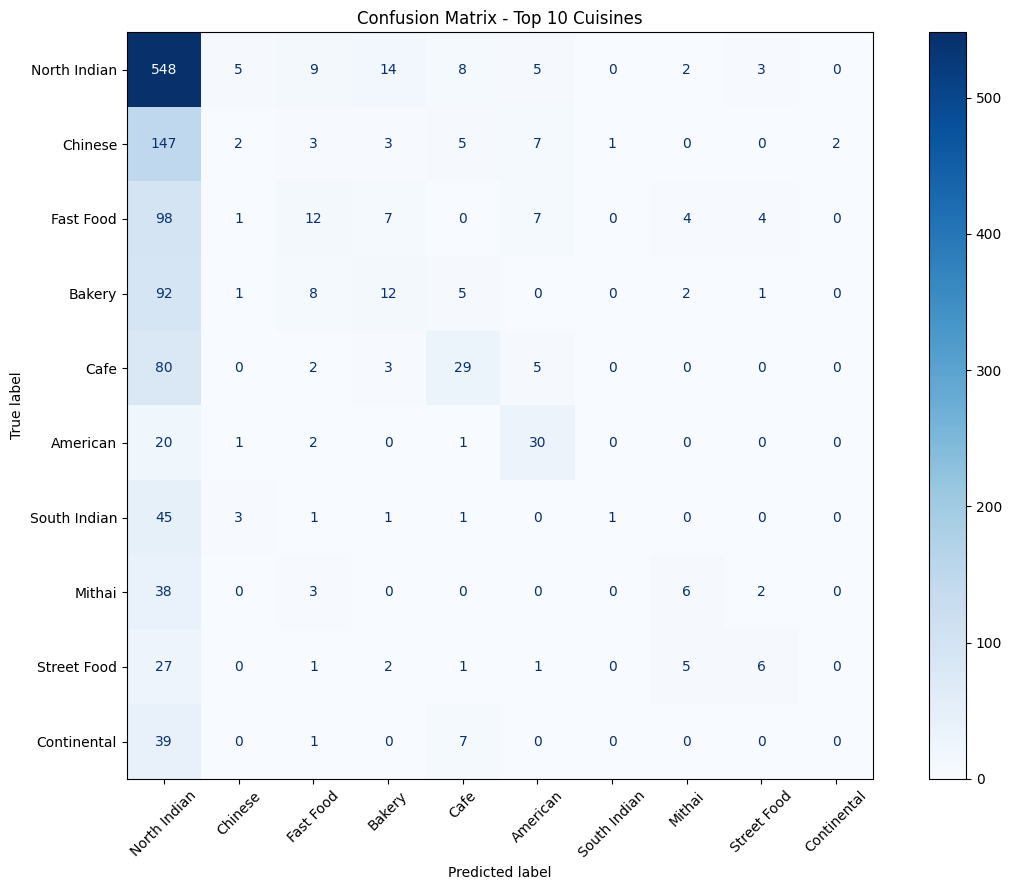

Confusion matrix saved successfully!


In [18]:
import os
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

os.makedirs("outputs", exist_ok=True)

top_cuisines = y_train.value_counts().head(10).index.tolist()
mask = y_test.isin(top_cuisines)

fig, ax = plt.subplots(figsize=(12, 9))

ConfusionMatrixDisplay.from_predictions(
    y_test[mask],
    best_pred[mask],
    labels=top_cuisines,
    xticks_rotation=45,
    cmap="Blues",
    values_format="d",
    ax=ax
)

plt.title("Confusion Matrix - Top 10 Cuisines")
plt.tight_layout()
plt.savefig("outputs/confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

print("Confusion matrix saved successfully!")

In [19]:
import joblib

os.makedirs("outputs", exist_ok=True)

joblib.dump(best_model, "outputs/cuisine_classification_model.pkl")

print("Model saved successfully!")
print("File: outputs/cuisine_classification_model.pkl")

Model saved successfully!
File: outputs/cuisine_classification_model.pkl


In [20]:
# Select one test restaurant
sample = X_test.iloc[[0]]
actual_cuisine = y_test.iloc[0]

predicted_cuisine = best_model.predict(sample)[0]

print("Sample Restaurant Features:")
print(sample.to_string(index=False))

print("\nActual Cuisine:", actual_cuisine)
print("Predicted Cuisine:", predicted_cuisine)
print(
    "Prediction Correct:",
    actual_cuisine == predicted_cuisine
)

Sample Restaurant Features:
 City  Price range  Average Cost for two  Aggregate rating  Votes Has Table booking Has Online delivery
Noida            2                   600               2.7     15                No                 Yes

Actual Cuisine: North Indian
Predicted Cuisine: North Indian
Prediction Correct: True


In [21]:
import os

for root, dirs, files in os.walk("outputs"):
    for file in files:
        print(os.path.join(root, file))

outputs/cuisine_classification_model.pkl
outputs/confusion_matrix.png


In [25]:
from google.colab import files

files.download("outputs/cuisine_classification_model.pkl")
files.download("outputs/confusion_matrix.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>